In [1]:
source(here::here('MG3.functions1.R')) # reloading the get the handles created


In [2]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM interestinggenes'
interestingGenes=dbGetQuery(mydbRO, queryTxt)[[1]]
processedGenes=readLines('~/data/lambda/output/step9Trees/plot_interesting_genes-2026-02-12_12.12.00.119328.swarm')
processedGenes=processedGenes[-1]
processedGenes=unlist(lapply(str_split(string = processedGenes, pattern = " "),FUN = function(x) return(x[[length(x)]]) ))

In [3]:
setdiff( processedGenes, interestingGenes)

[1] "ENSG00000140374"

In [4]:
setdiff(interestingGenes, processedGenes)

character(0)

In [5]:
queryTxt='SELECT COUNT( DISTINCT ensembl_gene_id ) FROM positively_ided_using_context'
dbGetQuery(mydbRO, queryTxt)

COUNT( DISTINCT ensembl_gene_id )
<int>
9608


In [6]:
queryTxt='SELECT * FROM interestinggenes'
interestingGenesDF=dbGetQuery(mydbRO, queryTxt)

## GTEx

In [7]:
queryTxt='SELECT DISTINCT ensembl_gene_id FROM HMMstats5MB'
HMMs=dbGetQuery(mydbRO, queryTxt)[[1]]


In [8]:
GTExDF=read.table("~/data/lambda/output/scratches/GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct", header = TRUE, sep="\t", skip = 2)

In [9]:
GTExDF$Description=NULL

In [10]:
GTExDF$Name=gsub(pattern = "\\.\\d+$", replacement = "", x = GTExDF$Name)
rownames(GTExDF)=GTExDF$Name
GTExDF$Name=NULL

In [11]:
ncol(GTExDF)

[1] 68

In [12]:
colnames(GTExDF)

[1] "Adipose_Subcutaneous"                             
 [2] "Adipose_Visceral_Omentum"                         
 [3] "Adrenal_Gland"                                    
 [4] "Artery_Aorta"                                     
 [5] "Artery_Coronary"                                  
 [6] "Artery_Tibial"                                    
 [7] "Bladder"                                          
 [8] "Brain_Amygdala"                                   
 [9] "Brain_Anterior_cingulate_cortex_BA24"             
[10] "Brain_Caudate_basal_ganglia"                      
[11] "Brain_Cerebellar_Hemisphere"                      
[12] "Brain_Cerebellum"                                 
[13] "Brain_Cortex"                                     
[14] "Brain_Frontal_Cortex_BA9"                         
[15] "Brain_Hippocampus"                                
[16] "Brain_Hypothalamus"                               
[17] "Brain_Nucleus_accumbens_basal_ganglia"            
[18] "Brain_Putamen_basal_ganglia"                      
[19] "Brain_Spinal_cord_cervical_c.1"                   
[20] "Brain_Substantia_nigra"                           
[21] "Breast_Mammary_Tissue"                            
[22] "Cells_Cultured_fibroblasts"                       
[23] "Cells_EBV.transformed_lymphocytes"                
[24] "Cervix_Ectocervix"                                
[25] "Cervix_Endocervix"                                
[26] "Colon_Sigmoid"                                    
[27] "Colon_Transverse"                                 
[28] "Colon_Transverse_Mixed_Cell"                      
[29] "Colon_Transverse_Mucosa"                          
[30] "Colon_Transverse_Muscularis"                      
[31] "Esophagus_Gastroesophageal_Junction"              
[32] "Esophagus_Mucosa"                                 
[33] "Esophagus_Muscularis"                             
[34] "Fallopian_Tube"                                   
[35] "Heart_Atrial_Appendage"                           
[36] "Heart_Left_Ventricle"                             
[37] "Kidney_Cortex"                                    
[38] "Kidney_Medulla"                                   
[39] "Liver"                                            
[40] "Liver_Hepatocyte"                                 
[41] "Liver_Mixed_Cell"                                 
[42] "Liver_Portal_Tract"                               
[43] "Lung"                                             
[44] "Minor_Salivary_Gland"                             
[45] "Muscle_Skeletal"                                  
[46] "Nerve_Tibial"                                     
[47] "Ovary"                                            
[48] "Pancreas"                                         
[49] "Pancreas_Acini"                                   
[50] "Pancreas_Islets"                                  
[51] "Pancreas_Mixed_Cell"                              
[52] "Pituitary"                                        
[53] "Prostate"                                         
[54] "Skin_Not_Sun_Exposed_Suprapubic"                  
[55] "Skin_Sun_Exposed_Lower_leg"                       
[56] "Small_Intestine_Terminal_Ileum"                   
[57] "Small_Intestine_Terminal_Ileum_Lymphoid_Aggregate"
[58] "Small_Intestine_Terminal_Ileum_Mixed_Cell"        
[59] "Spleen"                                           
[60] "Stomach"                                          
[61] "Stomach_Mixed_Cell"                               
[62] "Stomach_Mucosa"                                   
[63] "Stomach_Muscularis"                               
[64] "Testis"                                           
[65] "Thyroid"                                          
[66] "Uterus"                                           
[67] "Vagina"                                           
[68] "Whole_Blood"

In [13]:
GTExDF_subset=GTExDF[HMMs, ]

In [14]:
nrow(GTExDF_subset)

[1] 9518

In [15]:
GTExDF_subset_t=t(GTExDF_subset)

In [16]:
GTExDF_subset_t_scaled=scale(GTExDF_subset_t)

In [17]:
GTExDF_testis = GTExDF_subset_t_scaled["Testis",]

In [18]:
GTExDF_testis_interesting = GTExDF_testis[ names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id]
GTExDF_testis_interesting_not50K = GTExDF_testis[ names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id[ interestingGenesDF$is50Kresult == 0]]

In [19]:
GTExDF_testis_interesting

ENSG00000001626 ENSG00000029559 ENSG00000081014 ENSG00000091651 ENSG00000094841 
   -0.220843312     0.054782498     0.435701020     3.545630865    -1.923746906 
ENSG00000111701 ENSG00000111879 ENSG00000112167 ENSG00000114767 ENSG00000115085 
   -0.171752713     4.558387106     7.592059721     0.392581151    -0.144663359 
ENSG00000115364 ENSG00000115840 ENSG00000115993 ENSG00000116793 ENSG00000118690 
   -0.230225068    -0.725282805    -0.651859943     2.965146358     7.045716904 
ENSG00000121621 ENSG00000123901 ENSG00000124370 ENSG00000124678 ENSG00000130119 
    5.052802192    -0.049528565    -0.992810496     8.124934114    -0.671262016 
ENSG00000130385 ENSG00000133997 ENSG00000135324 ENSG00000135355 ENSG00000136319 
    7.993853176     0.394188974    -0.125646419     8.124417468     2.861659404 
ENSG00000139921 ENSG00000144644 ENSG00000144848 ENSG00000151131 ENSG00000151876 
   -0.213171337     0.009304157     5.214161794     0.441717603     1.494761914 
ENSG00000152990 ENSG00000163012 ENSG00000164082 ENSG00000166133 ENSG00000167769 
   -0.304600700     8.014398104     5.649932897     1.146046215    -0.072617009 
ENSG00000170289 ENSG00000170500 ENSG00000177103 ENSG00000177575 ENSG00000183060 
    7.189826208    -0.378504631     0.463402104    -0.495569516     1.176994568 
ENSG00000188282 ENSG00000203760 
   -0.162380196     4.233220252

In [20]:
GTExDF_testis_other = GTExDF_testis[! names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id]

In [21]:
GTExDF_summary=data.frame(ensembl_gene_id=names(GTExDF_testis), zscore=GTExDF_testis, 
                          interesting=names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id, 
                          interesting_not50K= names(GTExDF_testis) %in% interestingGenesDF$ensembl_gene_id[ interestingGenesDF$is50Kresult == 0]  )
GTExDF_summary$interesting_comprehensive_numb=as.integer(GTExDF_summary$interesting) + as.integer(GTExDF_summary$interesting_not50K)
GTExDF_summary$interesting_comprehensive=NA
GTExDF_summary$interesting_comprehensive[GTExDF_summary$interesting_comprehensive_numb==0]="Not flagged"
GTExDF_summary$interesting_comprehensive[GTExDF_summary$interesting_comprehensive_numb==1]="Flagged,\nno expansion"
GTExDF_summary$interesting_comprehensive[GTExDF_summary$interesting_comprehensive_numb==2]="Flagged,\ngenomic space expansion"

In [22]:
table(GTExDF_summary$interesting_comprehensive)


Flagged,\ngenomic space expansion            Flagged,\nno expansion 
                               31                                11 
                      Not flagged 
                             9476 

In [23]:
nrow(GTExDF_summary)

[1] 9518

In [24]:
library(ggsignif)


Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”


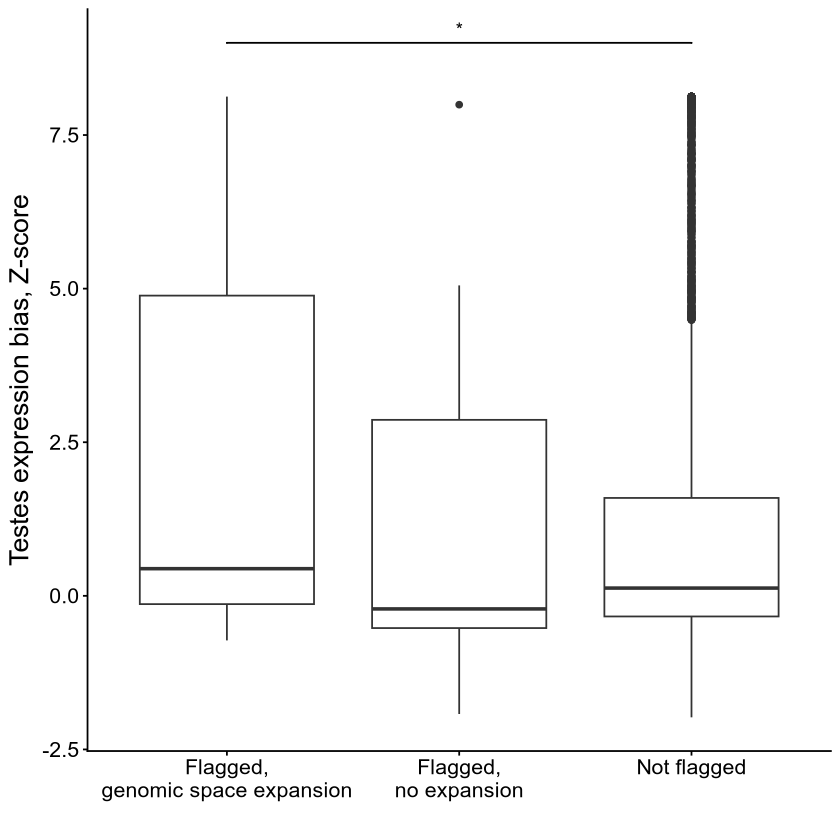

In [25]:
bplot=ggplot(GTExDF_summary, aes(x=interesting_comprehensive, y=zscore)) + geom_boxplot() + ylab("Testes expression bias, Z-score") + xlab("") +
geom_signif(
    y_position = 9, xmin = 1, xmax = 3,
    annotation = "*", tip_length = 0
  ) + theme_classic() + theme(text = element_text(size = 16))
bplot

In [26]:
source(here::here('MG3.functions9.R')) # reloading the get the handles created


In [28]:
saveFigurePlain(GGfigure = bplot, figName = "testes_expression_boxplot_3groups", outputDir = "~/data/lambda/output/", width.in = 8, height.in = 6)

Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range (`stat_signif()`).”
102554



In [27]:
mean(GTExDF_summary$zscore[!GTExDF_summary$interesting_comprehensive == "Not flagged"])

[1] 2.062885

In [28]:
t.test(GTExDF_summary$zscore[!GTExDF_summary$interesting_comprehensive == "Not flagged"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"],)


	Welch Two Sample t-test

data:  GTExDF_summary$zscore[!GTExDF_summary$interesting_comprehensive == "Not flagged"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"]
t = 2.039, df = 41.185, p-value = 0.0479
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 0.009602951 1.972656223
sample estimates:
mean of x mean of y 
 2.062885  1.071755 


In [29]:
t.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\ngenomic space expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"])


	Welch Two Sample t-test

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"]
t = 2.221, df = 30.099, p-value = 0.03402
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 0.1018782 2.4255887
sample estimates:
mean of x mean of y 
 2.335489  1.071755 


In [30]:
t.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\nno expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"])


	Welch Two Sample t-test

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\nno expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"]
t = 0.2378, df = 10.012, p-value = 0.8168
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -1.865113  2.310877
sample estimates:
mean of x mean of y 
 1.294638  1.071755 


In [31]:
t.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\nno expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"])


	Welch Two Sample t-test

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\nno expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"]
t = -0.94972, df = 17.909, p-value = 0.3549
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -3.344213  1.262511
sample estimates:
mean of x mean of y 
 1.294638  2.335489 


In [32]:
median(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\ngenomic space expansion"])

[1] 0.4417176

In [33]:
median(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\nno expansion"])

[1] -0.2131713

In [34]:
median(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Not flagged"], na.rm = TRUE)

[1] 0.125958

In [35]:
wilcox.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\ngenomic space expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"])


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"]
W = 182609, p-value = 0.0186
alternative hypothesis: true location shift is not equal to 0


In [36]:
wilcox.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\nno expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"])


	Wilcoxon rank sum test with continuity correction

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\nno expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Not flagged"]
W = 46432, p-value = 0.5343
alternative hypothesis: true location shift is not equal to 0


In [37]:
wilcox.test(GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive=="Flagged,\nno expansion"], GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"])


	Wilcoxon rank sum exact test

data:  GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\nno expansion"] and GTExDF_summary$zscore[GTExDF_summary$interesting_comprehensive == "Flagged,\ngenomic space expansion"]
W = 114, p-value = 0.11
alternative hypothesis: true location shift is not equal to 0
